In [3]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
from src.config import FIGURES_DIR
from src.data_utils import load_raw_data
from src.preprocessing import split_train_test, build_pipeline_a, build_pipeline_b

# 1. Đọc dữ liệu thô và tách Train/Test
df_raw = load_raw_data()
X_train, X_test, y_train, y_test = split_train_test(df_raw)

print(f"Kích thước tập Train: {X_train.shape} | Tỷ lệ Bad (1): {y_train.mean()*100:.1f}%")
print(f"Kích thước tập Test : {X_test.shape} | Tỷ lệ Bad (1): {y_test.mean()*100:.1f}%")

# 2. Fit trên tập Train và Transform trên cả Train/Test cho Luồng A
pipe_a = build_pipeline_a()
X_train_a = pipe_a.fit_transform(X_train, y_train)
X_test_a = pipe_a.transform(X_test)

# 3. Fit trên tập Train và Transform trên cả Train/Test cho Luồng B
pipe_b = build_pipeline_b()
X_train_b = pipe_b.fit_transform(X_train, y_train)
X_test_b = pipe_b.transform(X_test)

print(f"\nSố chiều đặc trưng sau xử lý của Luồng A (Cơ bản)  : {X_train_a.shape[1]} cột")
print(f"Số chiều đặc trưng sau xử lý của Luồng B (Cải tiến): {X_train_b.shape[1]} cột")

Kích thước tập Train: (800, 20) | Tỷ lệ Bad (1): 30.0%
Kích thước tập Test : (200, 20) | Tỷ lệ Bad (1): 30.0%

Số chiều đặc trưng sau xử lý của Luồng A (Cơ bản)  : 48 cột
Số chiều đặc trưng sau xử lý của Luồng B (Cải tiến): 41 cột


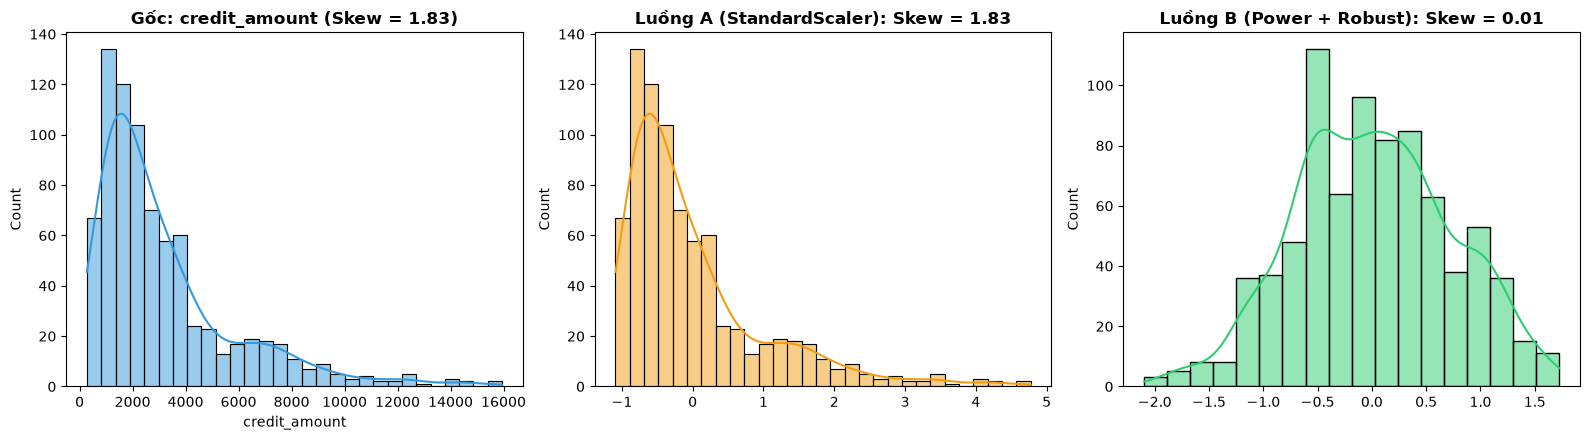

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Biểu đồ 1: Dữ liệu gốc của credit_amount
sns.histplot(X_train["credit_amount"], kde=True, ax=axes[0], color="#3498db")
axes[0].set_title(f"Gốc: credit_amount (Skew = {X_train['credit_amount'].skew():.2f})", fontweight="bold")

# Biểu đồ 2: Sau StandardScaler của Luồng A (cột số thứ 2 trong NUMERICAL_COLS)
credit_amt_a = X_train_a[:, 1]
sns.histplot(credit_amt_a, kde=True, ax=axes[1], color="#f39c12")
axes[1].set_title(f"Luồng A (StandardScaler): Skew = {pd.Series(credit_amt_a).skew():.2f}", fontweight="bold")

# Biểu đồ 3: Sau PowerTransformer + RobustScaler của Luồng B
credit_amt_b = X_train_b[:, 1]
sns.histplot(credit_amt_b, kde=True, ax=axes[2], color="#2ecc71")
axes[2].set_title(f"Luồng B (Power + Robust): Skew = {pd.Series(credit_amt_b).skew():.2f}", fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_preprocessing_comparison.png", dpi=300)
plt.show()

In [5]:
import joblib
from src.config import BASE_DIR
from src.modeling import evaluate_baselines_cv, run_grid_search_experiments, build_full_pipeline, get_base_models

print("=== KẾT QUẢ 5-FOLD CROSS-VALIDATION CỦA MÔ HÌNH BASELINE (MẶC ĐỊNH) ===")
baseline_cv_df = evaluate_baselines_cv(X_train, y_train)
display(baseline_cv_df.round(4))

=== KẾT QUẢ 5-FOLD CROSS-VALIDATION CỦA MÔ HÌNH BASELINE (MẶC ĐỊNH) ===


,Stream,Model,Stage,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,CV_Avg_Cost
0,Luồng A,K-NN,Baseline (Default),0.7375,0.6102,0.3542,0.4470,0.6952,166.0
1,Luồng A,Naive Bayes,Baseline (Default),0.6413,0.4653,0.6750,0.5381,0.7062,119.8
2,Luồng A,Decision Tree,Baseline (Default),0.6637,0.4439,0.4500,0.4463,0.6027,159.4
3,Luồng B,K-NN,Baseline (Default),0.7363,0.5792,0.4333,0.4937,0.7318,151.0
4,Luồng B,Naive Bayes,Baseline (Default),0.6462,0.4805,0.6250,0.5222,0.7182,128.6
5,Luồng B,Decision Tree,Baseline (Default),0.6550,0.4327,0.4667,0.4484,0.6012,157.6


In [6]:
print("=== KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ (GRIDSEARCHCV 5-FOLD) ===")
tuned_cv_df, best_models = run_grid_search_experiments(X_train, y_train)
display(tuned_cv_df.round(4))

# In chi tiết bộ siêu tham số tốt nhất của từng cấu hình
for index, row in tuned_cv_df.iterrows():
    print(f"[{row['Stream']} - {row['Model']}] F1: {row['CV_F1']:.4f} | Cost: {row['CV_Avg_Cost']:.1f} | Params: {row['Best_Params']}")

# Lưu các mô hình Baseline trên Luồng A và các mô hình Tuned để dùng cho Giai đoạn 5 & 6
models_dir = BASE_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

baseline_models = {}
for name, model in get_base_models().items():
    pipe = build_full_pipeline("A", model)
    pipe.fit(X_train, y_train)
    baseline_models[f"Baseline_A_{name}"] = pipe

joblib.dump(baseline_models, models_dir / "baseline_models.pkl")
joblib.dump(best_models, models_dir / "tuned_models.pkl")
print(f"\nĐã lưu toàn bộ mô hình vào thư mục: {models_dir}")

=== KẾT QUẢ TINH CHỈNH SIÊU THAM SỐ (GRIDSEARCHCV 5-FOLD) ===


,Stream,Model,Stage,Best_Params,CV_Accuracy,CV_Precision,CV_Recall,CV_F1,CV_ROC_AUC,CV_Avg_Cost
0,Luồng A,K-NN,Tuned (GridSearchCV),"{'metric': 'manhattan', 'n_neighbors': 3, 'wei...",0.7337,0.5808,0.4000,0.4725,0.7001,157.8
1,Luồng A,Naive Bayes,Tuned (GridSearchCV),{'var_smoothing': np.float64(0.0001)},0.6875,0.4885,0.6583,0.5570,0.7066,115.6
2,Luồng A,Decision Tree,Tuned (GridSearchCV),"{'class_weight': 'balanced', 'criterion': 'ent...",0.6738,0.4735,0.7625,0.5839,0.7245,97.8
3,Luồng B,K-NN,Tuned (GridSearchCV),"{'metric': 'euclidean', 'n_neighbors': 11, 'we...",0.7562,0.6344,0.4333,0.5120,0.7626,147.8
4,Luồng B,Naive Bayes,Tuned (GridSearchCV),{'var_smoothing': np.float64(0.0001)},0.6962,0.5035,0.6000,0.5401,0.7186,125.4
5,Luồng B,Decision Tree,Tuned (GridSearchCV),"{'class_weight': 'balanced', 'criterion': 'gin...",0.6825,0.4815,0.6958,0.5673,0.6943,109.2


[Luồng A - K-NN] F1: 0.4725 | Cost: 157.8 | Params: {'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}
[Luồng A - Naive Bayes] F1: 0.5570 | Cost: 115.6 | Params: {'var_smoothing': np.float64(0.0001)}
[Luồng A - Decision Tree] F1: 0.5839 | Cost: 97.8 | Params: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 10}
[Luồng B - K-NN] F1: 0.5120 | Cost: 147.8 | Params: {'metric': 'euclidean', 'n_neighbors': 11, 'weights': 'distance'}
[Luồng B - Naive Bayes] F1: 0.5401 | Cost: 125.4 | Params: {'var_smoothing': np.float64(0.0001)}
[Luồng B - Decision Tree] F1: 0.5673 | Cost: 109.2 | Params: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}

Đã lưu toàn bộ mô hình vào thư mục: D:\Học\Machine Learning\BTL\models


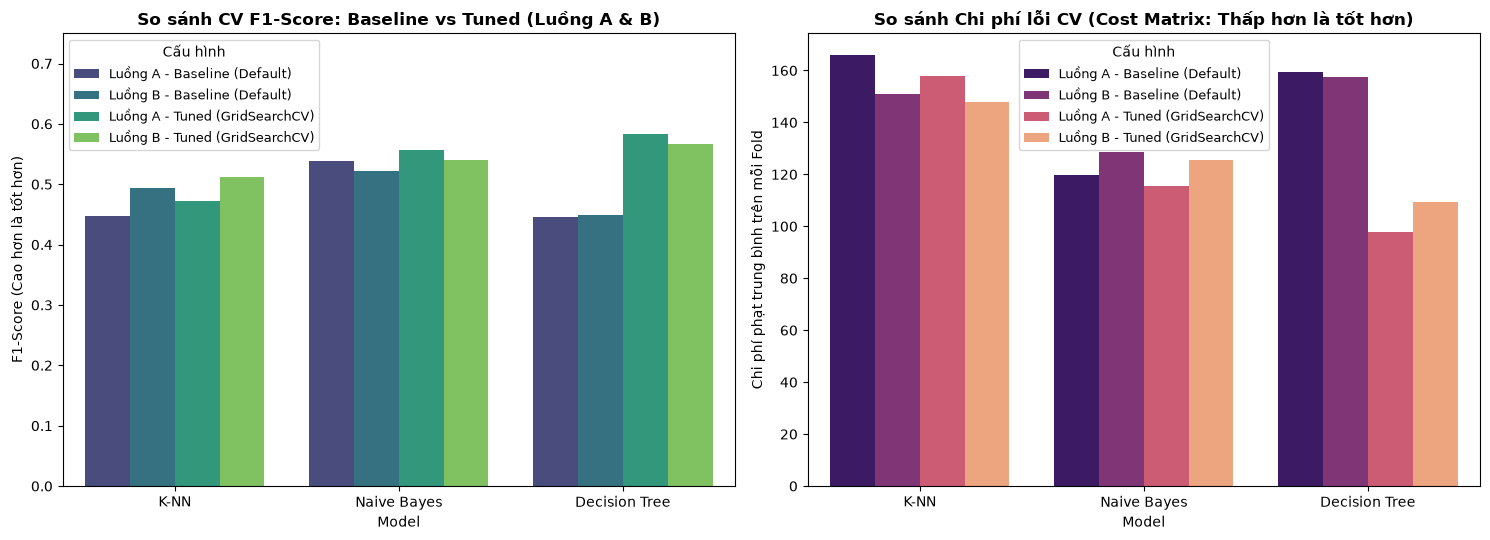

In [7]:
comparison_cv_df = pd.concat([
    baseline_cv_df.drop(columns=[], errors="ignore"),
    tuned_cv_df.drop(columns=["Best_Params"], errors="ignore")
], ignore_index=True)

comparison_cv_df["Config"] = comparison_cv_df["Stream"] + " - " + comparison_cv_df["Stage"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Biểu đồ 1: So sánh điểm F1-score trung bình qua 5-Fold CV
sns.barplot(
    data=comparison_cv_df, x="Model", y="CV_F1", hue="Config",
    ax=axes[0], palette="viridis"
)
axes[0].set_title("So sánh CV F1-Score: Baseline vs Tuned (Luồng A & B)", fontweight="bold")
axes[0].set_ylabel("F1-Score (Cao hơn là tốt hơn)")
axes[0].set_ylim(0, 0.75)
axes[0].legend(title="Cấu hình", fontsize=9)

# Biểu đồ 2: So sánh Chi phí sai số tín dụng trung bình (Cost Matrix)
sns.barplot(
    data=comparison_cv_df, x="Model", y="CV_Avg_Cost", hue="Config",
    ax=axes[1], palette="magma"
)
axes[1].set_title("So sánh Chi phí lỗi CV (Cost Matrix: Thấp hơn là tốt hơn)", fontweight="bold")
axes[1].set_ylabel("Chi phí phạt trung bình trên mỗi Fold")
axes[1].legend(title="Cấu hình", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_model_training_cv_comparison.png", dpi=300)
plt.show()